# Task 2: Player Segment Classification

**Goal:** classify each player as **Casual (0)**, **Grinder (1)**, **Social (2)** or **Whale (3)** so marketing can target each segment.
**Metric:** macro F1 (every segment counts equally).

**Final model:** smoothed Naive Bayes + spline logistic regression, blended in log space, with per-class weights.
5-fold CV macro F1 **≈ 0.757**; public leaderboard ≈ 0.755 for Task 2.

**How to run:** put the Kaggle `train.csv` and `test.csv` in this `task2/` folder, then run all cells (about 15 minutes on a laptop CPU).
The output is `task2_prediction.csv` (`player_id`, `task2`), in the same row order as `test.csv`.

| Section | Content |
|---|---|
| 1 | Setup and data |
| 2 | Exploratory data analysis |
| 3 | `player_id` leakage audit |
| 4 | Feature engineering and ablation |
| 5 | Models: from-scratch Naive Bayes plus five tuned models |
| 6 | Improvements tried: SMOTE, class weights, stacking, blends |
| 7 | Why the score stops near 0.757 |
| 8 | Final model and prediction file |
| 9 | Conclusions |

## 1. Setup and data

In [1]:
import json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
from sklearn.metrics import f1_score, log_loss, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score

TRAIN_PATH, TEST_PATH = "train.csv", "test.csv"
ID_COL, TARGET = "player_id", "segment"
CLASS_NAMES = {0: "Casual", 1: "Grinder", 2: "Social", 3: "Whale"}
ORDER = list(CLASS_NAMES.values())
NOISE_COLS = ["random_metric_1", "random_metric_2", "random_metric_3"]   # datacard: pure noise
CAT_COLS = ["region", "platform", "device_type", "payment_method", "language", "account_status",
            "player_type_tag", "engagement_level", "loyalty_tier", "skill_tier"]
SEED = 42

def numeric_cols(df):
    skip = {ID_COL, TARGET, *CAT_COLS}
    return [c for c in df.columns if c not in skip]

sns.set_theme(style="whitegrid")
PALETTE = {"Casual": "#4C72B0", "Grinder": "#DD8452", "Social": "#55A868", "Whale": "#C44E52"}

train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)
y = train[TARGET].to_numpy()
seg = train[TARGET].map(CLASS_NAMES)
NUM = numeric_cols(train)
print("train:", train.shape, " test:", test.shape, f" numeric: {len(NUM)}  categorical: {len(CAT_COLS)}")

train: (104000, 46)  test: (25889, 45)  numeric: 34  categorical: 10


## 2. Exploratory data analysis

### 2.1 Target distribution

,players,share
segment,,
Casual,40957,0.394
Grinder,26032,0.250
Social,21029,0.202
Whale,15982,0.154


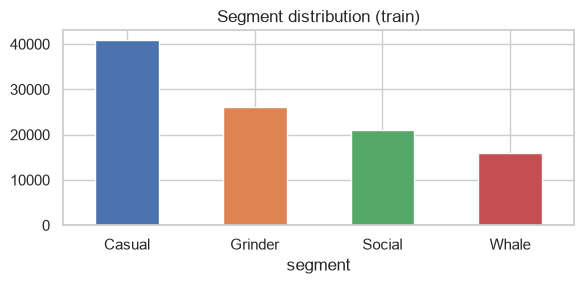

In [2]:
vc = seg.value_counts().reindex(ORDER)
display(pd.DataFrame({"players": vc, "share": (vc / len(train)).round(3)}))
ax = vc.plot.bar(color=[PALETTE[k] for k in ORDER], figsize=(6, 3), rot=0); ax.set_title("Segment distribution (train)")
plt.tight_layout(); plt.show()

The imbalance is mild, but macro F1 weights each class equally, so the smallest class (Whale) matters as much as Casual.

### 2.2 Missing values

In [3]:
miss = (train.drop(columns=[TARGET]).isna().mean() * 100).sort_values(ascending=False)
print(f"columns with missing values: {(miss > 0).sum()} of {len(miss)}; typical rate {miss.median():.1f}%; "
      f"highest: {miss.index[0]} {miss.iloc[0]:.0f}%, {miss.index[1]} {miss.iloc[1]:.0f}%")
print(f"rows with at least one missing value: {train.isna().any(axis=1).mean():.1%}")
by_seg = train[NUM + CAT_COLS].isna().groupby(seg).mean().T * 100
print(f"largest difference in missing rate between segments: {(by_seg.max(axis=1) - by_seg.min(axis=1)).max():.2f} points")

columns with missing values: 44 of 45; typical rate 7.7%; highest: payment_method 31%, region 26%
rows with at least one missing value: 98.2%
largest difference in missing rate between segments: 0.76 points


Almost every row has a gap, so dropping rows is not an option. Missing rates are the same in every segment, so the
missingness itself carries no signal. Models either skip missing values (Naive Bayes), handle them natively (trees) or impute them.

### 2.3 Data quality

In [4]:
checks = {
    "duplicate rows": int(train.drop(columns=[ID_COL]).duplicated().sum()),
    "player_id shared by train and test": len(set(train[ID_COL]) & set(test[ID_COL])),
    "negative spending": int((train[["total_spending_thb", "avg_monthly_spending"]] < 0).sum().sum()),
    "play_frequency > 7 ('days per week')": int((train["play_frequency"] > 7).sum()),
    "peak_concurrent_hours > 24": int((train["peak_concurrent_hours"] > 24).sum()),
}
display(pd.Series(checks, name="rows").to_frame())

,rows
duplicate rows,0
player_id shared by train and test,0
negative spending,0
play_frequency > 7 ('days per week'),69375
peak_concurrent_hours > 24,74820


No duplicates or overlap. Two columns don't match their description (`play_frequency` above 7 "days per week",
`peak_concurrent_hours` above 24) for most rows. They are probably on a different scale, and tree and rank-based models don't depend on units, so they are kept unchanged.

### 2.4 How segments differ

In [5]:
med = train.groupby(seg)[[c for c in NUM if c not in NOISE_COLS]].median().T[ORDER]
med["max/min"] = (med.max(axis=1) / med.min(axis=1).replace(0, np.nan)).round(2)
display(med.round(1).sort_values("max/min", ascending=False).head(16))

segment,Casual,Grinder,Social,Whale,max/min
avg_monthly_spending,2565.0,2841.6,3797.6,4525.6,1.8
spending_frequency,13.2,14.6,19.5,23.1,1.8
rare_items_count,66.0,74.0,99.0,116.0,1.8
total_spending_thb,26139.3,28611.5,38179.4,45092.7,1.7
friend_invites_sent,34.0,49.0,36.0,51.0,1.5
days_since_last_login,52.5,37.2,49.8,36.6,1.4
login_streak,44.0,61.0,46.0,63.0,1.4
total_playtime_hours,1388.7,1976.8,1470.0,2015.1,1.4
avg_session_duration,90.2,119.0,93.7,123.0,1.4
friend_count,87.0,123.0,90.0,126.0,1.4


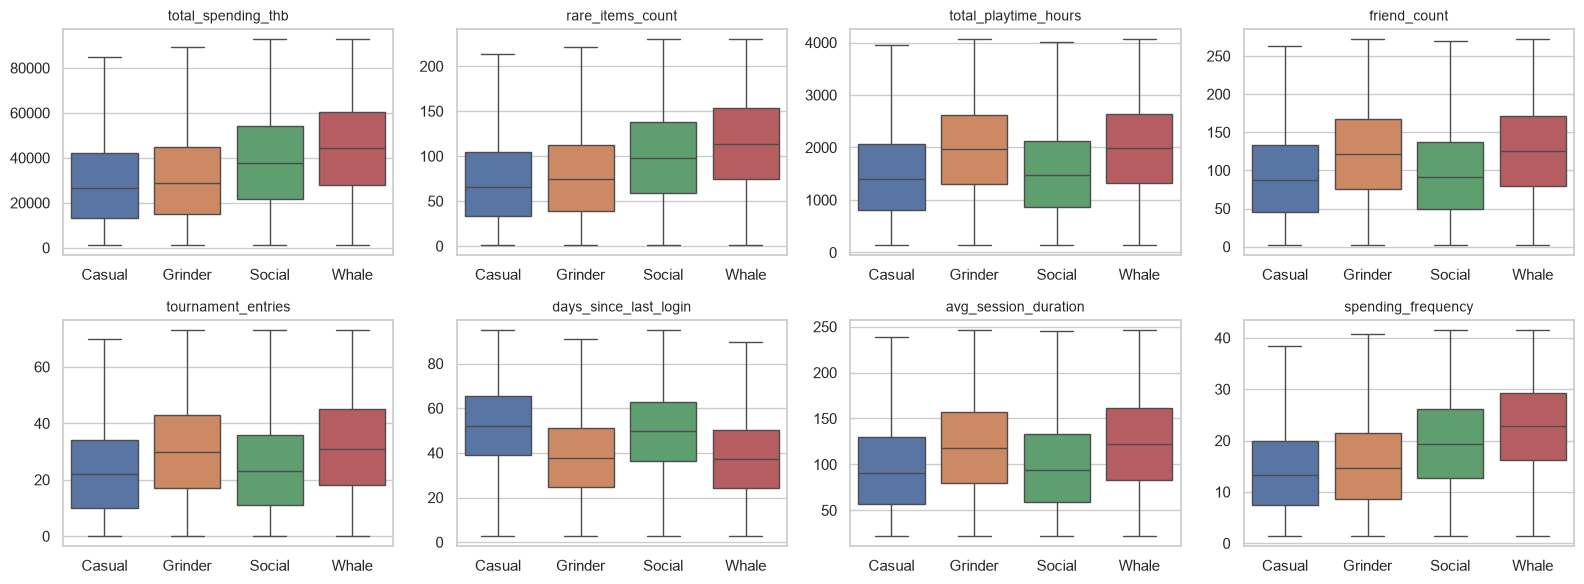

In [6]:
show = ["total_spending_thb", "rare_items_count", "total_playtime_hours", "friend_count",
        "tournament_entries", "days_since_last_login", "avg_session_duration", "spending_frequency"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.flat, show):
    lo, hi = train[c].quantile([.01, .99])
    sns.boxplot(x=seg[train[c].between(lo, hi)], y=train.loc[train[c].between(lo, hi), c], order=ORDER,
                palette=PALETTE, ax=ax, showfliers=False)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

The segments form a **2×2 grid**:

| | low spending | high spending |
|---|---|---|
| **low engagement** | Casual | Social |
| **high engagement** | Grinder | Whale |

- **Engagement** columns (playtime, sessions, logins, friends, tournaments, inverse `days_since_last_login`) are about 1.4× higher for Grinder and Whale.
- **Spending** columns (total/monthly spend, purchase frequency, rare items, VIP tier) are about 1.75× higher for Social and Whale.
- Each column on its own is a weak signal, and the distributions overlap heavily.

### 2.5 Categorical columns

In [7]:
base = seg.value_counts(normalize=True)
rows = {}
for c in CAT_COLS:
    ct = pd.crosstab(train[c].fillna("NA"), seg, normalize="index")
    rows[c] = (ct - base).abs().values.max()
display(pd.Series(rows, name="largest shift in a segment share").sort_values(ascending=False).round(3).to_frame())
display(pd.crosstab(train["loyalty_tier"].fillna("NA"), seg, normalize="index")[ORDER].round(2))

,largest shift in a segment share
loyalty_tier,0.385
engagement_level,0.383
language,0.008
device_type,0.007
skill_tier,0.007
region,0.004
player_type_tag,0.004
account_status,0.004
platform,0.004
payment_method,0.003


segment,Casual,Grinder,Social,Whale
loyalty_tier,,,,
Bronze,0.60,0.38,0.01,0.01
Diamond,0.01,0.01,0.56,0.42
Gold,0.23,0.15,0.35,0.27
NA,0.40,0.25,0.20,0.15
Platinum,0.01,0.01,0.56,0.42
Silver,0.48,0.30,0.13,0.10


Only `loyalty_tier` (a spending proxy: Bronze → Casual/Grinder, Platinum/Diamond → Social/Whale) and
`engagement_level` (an engagement proxy) carry signal. The other eight, including the promising-sounding `player_type_tag`, are noise.

### 2.6 Correlations, and the key finding: independence within each segment

In [8]:
num = [c for c in NUM if c not in NOISE_COLS]
def corr_stats(df):
    m = df[num].corr().abs().to_numpy(); t = m[np.triu_indices_from(m, 1)]
    return {"max |corr|": t.max(), "mean |corr|": t.mean()}
stats = {name: corr_stats(train[y == k]) for k, name in CLASS_NAMES.items()}
stats["all players pooled"] = corr_stats(train)
display(pd.DataFrame(stats).T.round(3))

,max |corr|,mean |corr|
Casual,0.017,0.005
Grinder,0.023,0.005
Social,0.024,0.007
Whale,0.040,0.010
all players pooled,0.153,0.025


Inside each segment the features are essentially **uncorrelated** (max |r| ≈ 0.02–0.04). The small pooled correlations appear only
because the features share a segment. The data looks as if it was generated as *segment → each feature drawn independently*.
That is exactly the **Naive Bayes assumption**, and it shapes the whole modelling approach below.

### 2.7 Do train and test look alike? (adversarial validation)

In [9]:
both = pd.concat([train[NUM + CAT_COLS].assign(is_test=0), test[NUM + CAT_COLS].assign(is_test=1)])
for c in CAT_COLS:
    both[c] = both[c].astype("category")
auc = cross_val_score(lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=SEED),
                      both.drop(columns="is_test"), both["is_test"], cv=3, scoring="roc_auc")
print(f"adversarial AUC: {auc.mean():.3f}  (0.5 = indistinguishable)")

adversarial AUC: 0.500  (0.5 = indistinguishable)


Train and test come from the same distribution, so cross-validation scores should match the leaderboard, which they did (CV 0.757, leaderboard ≈ 0.755).

## 3. `player_id` leakage audit
In the **original** Task 2 release, IDs were issued in blocks by segment (P0–52k Casual, 52k–84.5k Grinder, 84.5k–110.5k Social,
110.5k–130k Whale). The ID alone predicted the segment with macro F1 0.968, and about 3% of labels had been randomly flipped.
We reported it, and on 13 Nov the organisers released corrected data. The check below confirms that the current IDs carry no signal.
**`player_id` is never used as a feature.**

In [10]:
pid = train[ID_COL].str[1:].astype(int)
display(pd.crosstab(pd.qcut(pid, 10), seg, normalize="index")[ORDER].round(3))

segment,Casual,Grinder,Social,Whale
player_id,,,,
"(-0.001, 12904.9]",0.397,0.243,0.208,0.152
"(12904.9, 25861.8]",0.399,0.256,0.194,0.152
"(25861.8, 38896.7]",0.391,0.257,0.197,0.155
"(38896.7, 51938.6]",0.393,0.244,0.206,0.157
"(51938.6, 64929.5]",0.394,0.248,0.203,0.155
"(64929.5, 77974.8]",0.392,0.251,0.208,0.148
"(77974.8, 91047.9]",0.391,0.254,0.196,0.159
"(91047.9, 103983.2]",0.393,0.254,0.202,0.152
"(103983.2, 116986.1]",0.397,0.247,0.203,0.153


## 4. Feature engineering
`FeatureBuilder` drops the 3 noise columns and 8 useless categoricals, ordinal-encodes `loyalty_tier` / `engagement_level`,
and adds **composite engagement and spending scores**: the average percentile rank across each group of columns.
Averaging many weak, independent signals gives a much stronger one. All statistics are fitted on training rows only.

In [11]:
"""Feature engineering for Task 2.

Key idea from EDA: segments form a 2x2 grid
    engagement (low/high)  x  spending (low/high)
    Casual = low/low, Grinder = high/low, Social = low/high, Whale = high/high.
Each raw column is only a weak, noisy signal for one axis, and columns are
nearly uncorrelated -> averaging many of them into one composite score per
axis should give a much stronger signal (and is robust to ~8% missing cells).

All fitted statistics are learned from TRAIN only (`FeatureBuilder.fit`) and
then applied to any frame, so the test set is never used for fitting.
"""
import numpy as np
import pandas as pd



# --- column groups (from EDA section 5) ---------------------------------
# sign = +1 if higher value -> more engaged / more spending, -1 if the reverse
ENGAGEMENT_COLS = {
    "play_frequency": 1, "avg_session_duration": 1, "total_playtime_hours": 1,
    "login_streak": 1, "days_since_last_login": -1, "peak_concurrent_hours": 1,
    "friend_count": 1, "friend_invites_sent": 1, "gifts_sent_received": 1,
    "chat_activity_score": 1, "tournament_entries": 1,
    "speed_of_progression": 1, "competitive_rank": 1,
}
SPENDING_COLS = {
    "total_spending_thb": 1, "avg_monthly_spending": 1,
    "spending_frequency": 1, "rare_items_count": 1, "vip_tier": 1,
}

# Categoricals with clear signal -> ordinal; the rest showed none (EDA section 6)
ORDINAL_MAPS = {
    "loyalty_tier": {"Bronze": 0, "Silver": 1, "Gold": 2, "Platinum": 3, "Diamond": 4},
    "engagement_level": {"Low": 0, "Mid": 1, "High": 2, "Veteran": 3},
}
USELESS_CATS = [c for c in CAT_COLS if c not in ORDINAL_MAPS]


def _safe_div(a, b):
    return a / b.replace(0, np.nan)


class FeatureBuilder:
    """Configurable feature pipeline; flags let us ablate each idea with CV."""

    def __init__(self, drop_noise=True, drop_useless_cats=True, ordinal=True,
                 composites=True, ratios=True, keep_raw=True):
        self.drop_noise = drop_noise
        self.drop_useless_cats = drop_useless_cats
        self.ordinal = ordinal
        self.composites = composites
        self.ratios = ratios
        self.keep_raw = keep_raw

    # ---- fit: store sorted train values for percentile-rank transform ----
    def fit(self, train: pd.DataFrame):
        cols = list(ENGAGEMENT_COLS) + list(SPENDING_COLS)
        self.sorted_ = {c: np.sort(train[c].dropna().to_numpy()) for c in cols}
        return self

    def _pct_rank(self, s: pd.Series) -> pd.Series:
        ref = self.sorted_[s.name]
        # mid-rank handles ties in discrete columns (e.g. vip_tier)
        lo = np.searchsorted(ref, s.to_numpy(), side="left")
        hi = np.searchsorted(ref, s.to_numpy(), side="right")
        r = (lo + hi) / 2 / len(ref)
        return pd.Series(np.where(s.isna(), np.nan, r), index=s.index)

    def _composite(self, df, group: dict, name: str) -> pd.DataFrame:
        ranks = pd.DataFrame({c: self._pct_rank(df[c]) if sign > 0 else 1 - self._pct_rank(df[c])
                              for c, sign in group.items()})
        return pd.DataFrame({
            f"{name}_score": ranks.mean(axis=1),            # NaN-aware mean
            f"{name}_score_std": ranks.std(axis=1),         # consistency across signals
            f"{name}_n_obs": ranks.notna().sum(axis=1),     # how many signals we saw
        })

    # ---- transform -------------------------------------------------------
    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        X = df.drop(columns=[c for c in (ID_COL, TARGET, "seg_name") if c in df.columns])
        new = []

        if self.composites:
            eng = self._composite(df, ENGAGEMENT_COLS, "eng")
            spd = self._composite(df, SPENDING_COLS, "spend")
            inter = pd.DataFrame({
                "eng_x_spend": eng["eng_score"] * spd["spend_score"],
                "eng_minus_spend": eng["eng_score"] - spd["spend_score"],
            })
            new += [eng, spd, inter]

        if self.ratios:
            new.append(pd.DataFrame({
                "spend_per_hour": _safe_div(X["total_spending_thb"], X["total_playtime_hours"]),
                "spend_per_txn": _safe_div(X["avg_monthly_spending"], X["spending_frequency"]),
                "spend_tenure_months": _safe_div(X["total_spending_thb"], X["avg_monthly_spending"]),
                "rare_per_spend": _safe_div(X["rare_items_count"], X["total_spending_thb"]) * 1000,
                "hours_per_day_played": _safe_div(X["total_playtime_hours"], X["account_age_days"]),
                "friends_per_hour": _safe_div(X["friend_count"], X["total_playtime_hours"]) * 100,
                "gifts_per_friend": _safe_div(X["gifts_sent_received"], X["friend_count"]),
                "session_x_freq": X["avg_session_duration"] * X["play_frequency"],
            }))

        if self.ordinal:
            for c, m in ORDINAL_MAPS.items():
                X[c] = X[c].map(m).astype(float)

        drop = []
        if self.drop_noise:
            drop += NOISE_COLS
        if self.drop_useless_cats:
            drop += USELESS_CATS
        if not self.keep_raw:  # keep only engineered + ordinals
            drop += [c for c in list(ENGAGEMENT_COLS) + list(SPENDING_COLS) if c in X]
        X = X.drop(columns=[c for c in drop if c in X.columns])

        X = pd.concat([X, *new], axis=1)
        for c in X.columns:  # remaining text columns -> pandas category for LightGBM
            if X[c].dtype == object or str(X[c].dtype) in ("str", "string"):
                X[c] = X[c].astype("category")
        return X

    def fit_transform(self, df):
        return self.fit(df).transform(df)

### Leak-free cross-validation helper
`cv_fit_in_fold` fits the `FeatureBuilder` inside each fold, so validation rows never influence the features.

In [12]:
"""Shared cross-validation helper so every experiment is scored the same way."""
import time

import numpy as np
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold




N_SPLITS = 5


def get_folds(y, n_splits=N_SPLITS, seed=SEED):
    return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def cv_fit_in_fold(model, train, y, view, folds, verbose=True):
    """Like cv_model, but fits the FeatureBuilder on each fold's training part
    only, so no validation-row statistics reach the features.
    Returns (oof_proba, macro_f1, per-fold f1 list)."""
    y = np.asarray(y)
    oof = np.zeros((len(y), len(np.unique(y))))
    fold_f1 = []
    t0 = time.time()
    for tr, va in folds:
        fb = FeatureBuilder(**view).fit(train.iloc[tr])
        Xtr, Xva = fb.transform(train.iloc[tr]), fb.transform(train.iloc[va])
        if ID_COL in Xtr.columns:
            raise ValueError("player_id must not be a feature")
        oof[va] = clone(model).fit(Xtr, y[tr]).predict_proba(Xva)
        fold_f1.append(f1_score(y[va], oof[va].argmax(1), average="macro"))
    score = f1_score(y, oof.argmax(1), average="macro")
    if verbose:
        print(f"macro F1 {score:.4f}  (folds {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f})"
              f"  [{Xtr.shape[1]} feats, {time.time() - t0:.0f}s]")
    return oof, score, fold_f1


def cv_model(model, X, y, folds=None, verbose=True):
    """Return (oof_proba [n, n_classes], macro_f1, per-fold f1 list)."""
    folds = folds or get_folds(y)
    y = np.asarray(y)
    oof = np.zeros((len(y), len(np.unique(y))))
    fold_f1 = []
    t0 = time.time()
    for tr, va in folds:
        m = clone(model).fit(X.iloc[tr], y[tr])
        oof[va] = m.predict_proba(X.iloc[va])
        fold_f1.append(f1_score(y[va], oof[va].argmax(1), average="macro"))
    score = f1_score(y, oof.argmax(1), average="macro")
    if verbose:
        print(f"macro F1 {score:.4f}  (folds {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f})"
              f"  [{X.shape[1]} feats, {time.time() - t0:.0f}s]")
    return oof, score, fold_f1

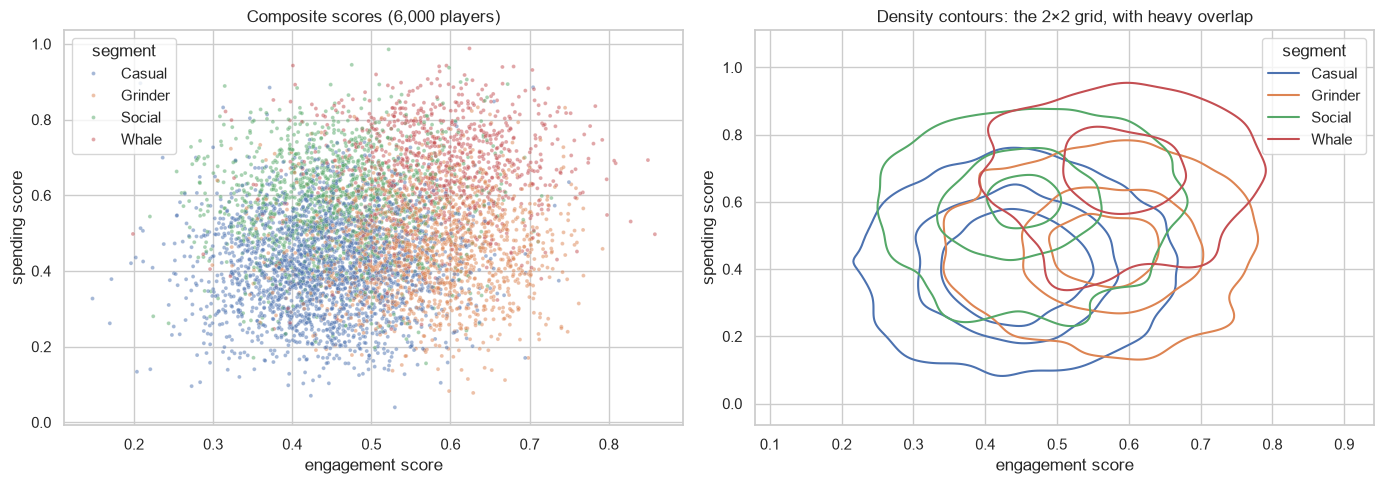

In [13]:
fb = FeatureBuilder().fit(train); Xf = fb.transform(train)
plot = pd.DataFrame({"engagement score": Xf["eng_score"], "spending score": Xf["spend_score"], "segment": seg}).sample(6000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=plot, x="engagement score", y="spending score", hue="segment", hue_order=ORDER, palette=PALETTE, s=8, alpha=.5, ax=axes[0])
sns.kdeplot(data=plot, x="engagement score", y="spending score", hue="segment", hue_order=ORDER, palette=PALETTE, levels=4, ax=axes[1])
axes[0].set_title("Composite scores (6,000 players)"); axes[1].set_title("Density contours: the 2×2 grid, with heavy overlap")
plt.tight_layout(); plt.show()

### 4.1 Ablation: add one idea at a time (LightGBM, same 5 folds)

In [14]:
folds = get_folds(y)
lgbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, verbose=-1, random_state=SEED)
configs = {
    "A raw features": dict(drop_noise=False, drop_useless_cats=False, ordinal=False, composites=False, ratios=False),
    "B drop noise + useless categoricals": dict(ordinal=False, composites=False, ratios=False),
    "C + ordinal tiers": dict(composites=False, ratios=False),
    "D + composite scores": dict(ratios=False),
    "E + ratio features": dict(),
    "F composites only (no raw columns)": dict(keep_raw=False),
}
ablation = {}
for name, cfg in configs.items():
    print(f"{name:38s}", end=" ")
    _, ablation[name], _ = cv_fit_in_fold(lgbm, train, y, cfg, folds)

A raw features                         

macro F1 0.7491  (folds 0.7491 ± 0.0027)  [44 feats, 40s]
B drop noise + useless categoricals    

macro F1 0.7479  (folds 0.7479 ± 0.0014)  [33 feats, 34s]
C + ordinal tiers                      

macro F1 0.7482  (folds 0.7482 ± 0.0026)  [33 feats, 34s]
D + composite scores                   

macro F1 0.7516  (folds 0.7516 ± 0.0017)  [41 feats, 38s]
E + ratio features                     

macro F1 0.7517  (folds 0.7517 ± 0.0023)  [49 feats, 40s]
F composites only (no raw columns)     

macro F1 0.7444  (folds 0.7444 ± 0.0031)  [31 feats, 31s]


Dropping the noise columns costs nothing, and composite scores give the only clear gain. Ratio features add nothing,
and composites can't replace the raw columns. The winning configuration is **D**, used for the tree models below.

## 5. Models
### 5.1 Naive Bayes written from scratch
Because the features are independent within each segment, the best possible classifier simply **adds up each feature's evidence**:
log P(segment | x) = log P(segment) + Σ log P(xⱼ | segment). Standard GaussianNB assumes bell-shaped features and does poorly here,
so the per-feature densities are estimated non-parametrically:
- **HistNB:** per-class histograms on quantile bins. A missing value adds no evidence, which is the statistically correct treatment.
- **AvgHistNB:** averages several bin counts to reduce sensitivity to where bin edges fall.
- **SmoothNB:** 200 fine bins smoothed with a Gaussian kernel, i.e. a binned kernel density estimate.

In [15]:
"""Custom models for Task 2.

HistNB — histogram Naive Bayes.
EDA showed features are (almost exactly) independent *within* each segment
(max within-class |corr| ~ 0.02). Under that condition the Bayes-optimal
classifier is

    log P(class | x) = log P(class) + sum_j log P(x_j | class) + const

so we only need a good 1-D density per feature per class. We estimate it
non-parametrically with quantile histograms (no Gaussian assumption) plus
Laplace smoothing. A missing value simply contributes nothing — the
statistically correct treatment, with no imputation needed.
"""
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d
from sklearn.base import BaseEstimator, ClassifierMixin


class HistNB(BaseEstimator, ClassifierMixin):
    def __init__(self, n_bins=32, alpha=1.0, discrete_max_unique=12, weight=1.0):
        self.n_bins = n_bins
        self.alpha = alpha                      # Laplace smoothing per bin
        self.discrete_max_unique = discrete_max_unique
        self.weight = weight                    # temperature on summed log-likelihood

    # -- helpers ----------------------------------------------------------
    def _bin(self, j, col: pd.Series) -> np.ndarray:
        """Map values to bin index; -1 for missing / unseen category."""
        kind, ref = self.spec_[j]
        if kind == "cat":
            mapped = pd.Series(col.astype(object).map(ref), index=col.index)
            return mapped.fillna(-1).to_numpy(dtype=int)
        v = col.to_numpy(dtype=float)
        idx = np.searchsorted(ref, v, side="right")   # 0..len(ref)
        idx[np.isnan(v)] = -1
        return idx

    def fit(self, X: pd.DataFrame, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        K = len(self.classes_)
        yi = np.searchsorted(self.classes_, y)
        self.log_prior_ = np.log(np.bincount(yi, minlength=K) / len(y))
        self.columns_ = list(X.columns)
        self.spec_, self.tables_ = [], []
        for j, c in enumerate(self.columns_):
            col = X[c]
            numeric = pd.api.types.is_numeric_dtype(col) and not isinstance(col.dtype, pd.CategoricalDtype)
            if not numeric or col.nunique() <= self.discrete_max_unique:
                cats = pd.Series(col.dropna().unique())
                self.spec_.append(("cat", {v: i for i, v in enumerate(cats)}))
                n = len(cats)
            else:
                qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
                edges = np.unique(np.nanquantile(col.to_numpy(dtype=float), qs))
                self.spec_.append(("num", edges))
                n = len(edges) + 1
            b = self._bin(j, col)
            ok = b >= 0
            counts = np.zeros((K, n))
            np.add.at(counts, (yi[ok], b[ok]), 1)
            self.tables_.append(self._log_table(self.spec_[j][0], counts))
        return self

    def _log_table(self, kind, counts):
        """Per-class log-probabilities of each bin (Laplace smoothed)."""
        counts = counts + self.alpha
        return np.log(counts / counts.sum(axis=1, keepdims=True))

    def log_likelihoods(self, X: pd.DataFrame) -> np.ndarray:
        """Per-feature class log-likelihoods, shape (n, n_features, K); 0 where missing."""
        out = np.zeros((len(X), len(self.columns_), len(self.classes_)))
        for j, c in enumerate(self.columns_):
            b = self._bin(j, X[c])
            ok = b >= 0
            out[ok, j, :] = self.tables_[j][:, b[ok]].T
        return out

    def decision_function(self, X):
        return self.log_prior_ + self.weight * self.log_likelihoods(X).sum(axis=1)

    def predict_proba(self, X):
        z = self.decision_function(X)
        z -= z.max(axis=1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


class SmoothNB(HistNB):
    """Naive Bayes with smoothed (kernel-style) per-class densities.

    Numeric features are cut into many fine quantile bins (default 200),
    then each class's bin counts are smoothed with a Gaussian kernel of
    width `sigma` bins. This is a binned kernel density estimate: it keeps
    the detail of fine bins without their noise, instead of choosing
    between a few coarse bins (HistNB) or averaging several binnings
    (AvgHistNB). Discrete features are handled exactly as in HistNB.
    """

    def __init__(self, n_bins=200, sigma=6.0, alpha=1.0, discrete_max_unique=12, weight=1.0):
        super().__init__(n_bins=n_bins, alpha=alpha, discrete_max_unique=discrete_max_unique, weight=weight)
        self.sigma = sigma

    def _log_table(self, kind, counts):
        if kind == "num" and self.sigma > 0:
            counts = gaussian_filter1d(counts, self.sigma, axis=1, mode="reflect")
        return super()._log_table(kind, counts)


class AvgHistNB(BaseEstimator, ClassifierMixin):
    """Average the log-posteriors of HistNB fitted with several bin counts.

    One histogram is sensitive to where its bin edges fall; averaging over
    several binnings is a cheap way to get a smoother density estimate
    (like an averaged shifted histogram) -> lower variance.
    """

    def __init__(self, bin_list=(10, 12, 14, 16, 20, 24, 28, 32), alpha=1.0):
        self.bin_list = bin_list
        self.alpha = alpha

    def fit(self, X, y):
        self.models_ = [HistNB(n_bins=b, alpha=self.alpha).fit(X, y) for b in self.bin_list]
        self.classes_ = self.models_[0].classes_
        return self

    def predict_proba(self, X):
        z = np.mean([m.decision_function(X) for m in self.models_], axis=0)
        z -= z.max(axis=1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

### 5.2 Blending, class weights and stacking helpers (scored with nested CV)

In [16]:
"""Blending OOF probabilities and per-class weight tuning for macro F1.

Both steps are *fitted* on OOF predictions, so their CV score would be
optimistic if measured on the same rows. `nested_score` gives an honest
estimate: for each fold, fit blend + class weights on the other folds' OOF
and score on the held-out fold.
"""
import numpy as np
from scipy.optimize import minimize
from sklearn.metrics import f1_score, log_loss


# ---- blending -------------------------------------------------------------
def blend(probs: list[np.ndarray], w: np.ndarray) -> np.ndarray:
    """Geometric (log-space) blend; suits well-calibrated probability models."""
    z = sum(wi * np.log(np.clip(p, 1e-12, 1)) for wi, p in zip(w, probs))
    z -= z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def fit_blend_weights(probs, y) -> np.ndarray:
    """Non-negative weights minimising log-loss (weights need not sum to 1:
    the total also acts as a temperature)."""
    k = len(probs)
    res = minimize(lambda w: log_loss(y, blend(probs, np.abs(w))), np.full(k, 1 / k),
                   method="Nelder-Mead", options={"xatol": 1e-3, "fatol": 1e-6, "maxiter": 400})
    return np.abs(res.x)


# ---- class weights ---------------------------------------------------------
def apply_class_weights(p, cw):
    return (p * cw).argmax(axis=1)


def fit_class_weights(p, y, grid=np.exp(np.linspace(-0.7, 0.7, 29)), n_rounds=3):
    """Coordinate ascent on per-class multipliers to maximise macro F1."""
    cw = np.ones(p.shape[1])
    best = f1_score(y, apply_class_weights(p, cw), average="macro")
    for _ in range(n_rounds):
        for k in range(1, p.shape[1]):          # class 0 fixed as reference
            for g in grid:
                trial = cw.copy(); trial[k] = g
                s = f1_score(y, apply_class_weights(p, trial), average="macro")
                if s > best + 1e-6:
                    best, cw = s, trial
    return cw, best


# ---- stacking --------------------------------------------------------------
def stack_features(probs):
    """Level-2 inputs: log-probabilities of every level-1 model, side by side."""
    return np.hstack([np.log(np.clip(p, 1e-12, 1)) for p in probs])


def fit_stacker(probs, y, C=1.0):
    from sklearn.linear_model import LogisticRegression
    return LogisticRegression(C=C, max_iter=3000).fit(stack_features(probs), y)


def nested_stack_score(probs, y, folds, use_cw=True, C=1.0):
    """Meta-model trained on 4 folds of OOF predictions, scored on the 5th."""
    y = np.asarray(y)
    pred = np.zeros(len(y), dtype=int)
    feats = stack_features(probs)
    for tr, va in folds:
        meta = fit_stacker([p[tr] for p in probs], y[tr], C)
        cw = fit_class_weights(meta.predict_proba(feats[tr]), y[tr])[0] if use_cw else np.ones(probs[0].shape[1])
        pred[va] = apply_class_weights(meta.predict_proba(feats[va]), cw)
    return f1_score(y, pred, average="macro")


# ---- honest evaluation -----------------------------------------------------
def nested_score(probs, y, folds, use_blend=True, use_cw=True):
    """Fit blend/class weights on 4 folds of OOF, score on the 5th."""
    y = np.asarray(y)
    pred = np.zeros(len(y), dtype=int)
    for tr, va in folds:
        ptr = [p[tr] for p in probs]
        w = fit_blend_weights(ptr, y[tr]) if (use_blend and len(probs) > 1) else np.ones(len(probs)) / len(probs)
        cw = fit_class_weights(blend(ptr, w), y[tr])[0] if use_cw else np.ones(probs[0].shape[1])
        pred[va] = apply_class_weights(blend([p[va] for p in probs], w), cw)
    return f1_score(y, pred, average="macro")

### 5.3 Model definitions

In [17]:
"""Features-only model definitions, shared by tune_models.py and 04_model_no_leak.

Each model has a feature "view" (FeatureBuilder settings). None of the views
contain player_id: FeatureBuilder.transform drops it.
"""
import catboost as cb
import lightgbm as lgb
import xgboost as xgb
from catboost.utils import get_gpu_device_count
from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer, SplineTransformer





VIEWS = {
    "nb": dict(ordinal=False, composites=False, ratios=False),  # raw values + text categories
    "lr": dict(composites=False, ratios=False),                 # raw values + ordinals
    "gb": dict(ratios=False),                                   # raw + ordinals + composite scores
}
MODEL_VIEW = {"AvgHistNB": "nb", "SplineLR": "lr", "LightGBM": "gb",
              "XGBoost": "gb", "CatBoost": "gb", "RandomForest": "gb"}

CAT_DEVICE = "GPU" if get_gpu_device_count() > 0 else "CPU"
BIN_LISTS = {
    "narrow": (12, 14, 16, 18, 20),
    "default": (10, 12, 14, 16, 20, 24, 28, 32),
    "wide": (8, 10, 12, 16, 20, 24, 32, 40, 48),
}


def _numeric_columns(X):
    return [c for c in X.columns if c not in ORDINAL_MAPS]


def _ordinal_columns(X):
    return [c for c in X.columns if c in ORDINAL_MAPS]


def build(name: str, params: dict):
    """Return an unfitted model. `params` holds tuned values only."""
    p = dict(params)
    if name == "AvgHistNB":
        return AvgHistNB(bin_list=BIN_LISTS[p["bins"]], alpha=p["alpha"])
    if name == "SplineLR":
        numeric = make_pipeline(
            SimpleImputer(strategy="median"),
            QuantileTransformer(subsample=50000, random_state=0),
            SplineTransformer(n_knots=p["n_knots"], degree=3))
        ordinal = make_pipeline(SimpleImputer(strategy="constant", fill_value=-1),
                                OneHotEncoder(handle_unknown="ignore"))
        return make_pipeline(make_column_transformer((numeric, _numeric_columns), (ordinal, _ordinal_columns)),
                             LogisticRegression(C=p["C"], max_iter=2000))
    if name == "LightGBM":
        return lgb.LGBMClassifier(**p, bagging_freq=1, verbose=-1, random_state=SEED)
    if name == "XGBoost":
        return xgb.XGBClassifier(**p, objective="multi:softprob", tree_method="hist", random_state=SEED)
    if name == "CatBoost":
        return cb.CatBoostClassifier(**p, loss_function="MultiClass", task_type=CAT_DEVICE,
                                     bootstrap_type="Bernoulli", verbose=0, random_seed=SEED,
                                     allow_writing_files=False)
    if name == "RandomForest":
        return RandomForestClassifier(**p, n_estimators=300, n_jobs=-1, random_state=SEED)
    raise ValueError(name)

### 5.4 Tuned hyperparameters
Tuned with **Optuna** on *separate* 3-fold splits (seed 2026), so the scores reported here (seed 42) aren't biased by the tuning.
The results are stored below. Set `RUN_TUNING = True` to re-run the search (about 6 minutes per model).

In [18]:
TUNED = json.loads('''{
  "AvgHistNB": {
    "bins": "wide",
    "alpha": 4.430317433764992
  },
  "SplineLR": {
    "C": 4.394842165614594,
    "n_knots": 4
  },
  "LightGBM": {
    "learning_rate": 0.05,
    "n_estimators": 353,
    "num_leaves": 13,
    "min_child_samples": 121,
    "feature_fraction": 0.4546002411859635,
    "bagging_fraction": 0.8472465399746438,
    "lambda_l2": 21.8212146053967
  },
  "XGBoost": {
    "learning_rate": 0.05,
    "n_estimators": 490,
    "max_depth": 5,
    "min_child_weight": 14.090927656763135,
    "subsample": 0.7450709428407195,
    "colsample_bytree": 0.3450260001503287,
    "reg_lambda": 0.46537683925546935
  },
  "CatBoost": {
    "learning_rate": 0.05,
    "iterations": 1991,
    "depth": 2,
    "l2_leaf_reg": 2.4774332740870584,
    "subsample": 0.8214484748875857
  },
  "RandomForest": {
    "max_depth": 17,
    "min_samples_leaf": 3,
    "max_features": 0.29350843229198187,
    "max_samples": 0.960628232412788,
    "class_weight": "balanced_subsample"
  }
}''')
RUN_TUNING = False

In [19]:
LR, MAX_ROUNDS, PATIENCE, TUNE_SEED = 0.05, 2000, 50, 2026


def space(name, t):
    if name == "AvgHistNB":
        return {"bins": t.suggest_categorical("bins", ["narrow", "default", "wide"]),
                "alpha": t.suggest_float("alpha", 0.1, 30, log=True)}
    if name == "SplineLR":
        return {"C": t.suggest_float("C", 0.02, 5, log=True), "n_knots": t.suggest_int("n_knots", 4, 9)}
    if name == "LightGBM":
        return {"learning_rate": LR, "n_estimators": MAX_ROUNDS,
                "num_leaves": t.suggest_int("num_leaves", 4, 64, log=True),
                "min_child_samples": t.suggest_int("min_child_samples", 20, 500, log=True),
                "feature_fraction": t.suggest_float("feature_fraction", 0.2, 0.9),
                "bagging_fraction": t.suggest_float("bagging_fraction", 0.5, 1.0),
                "lambda_l2": t.suggest_float("lambda_l2", 1e-3, 50, log=True)}
    if name == "XGBoost":
        return {"learning_rate": LR, "n_estimators": MAX_ROUNDS, "early_stopping_rounds": PATIENCE,
                "max_depth": t.suggest_int("max_depth", 2, 8),
                "min_child_weight": t.suggest_float("min_child_weight", 1, 100, log=True),
                "subsample": t.suggest_float("subsample", 0.5, 1.0),
                "colsample_bytree": t.suggest_float("colsample_bytree", 0.2, 0.9),
                "reg_lambda": t.suggest_float("reg_lambda", 1e-2, 50, log=True)}
    if name == "CatBoost":
        return {"learning_rate": LR, "iterations": MAX_ROUNDS,
                "depth": t.suggest_int("depth", 2, 8),
                "l2_leaf_reg": t.suggest_float("l2_leaf_reg", 1, 50, log=True),
                "subsample": t.suggest_float("subsample", 0.5, 1.0)}
    if name == "RandomForest":
        return {"max_depth": t.suggest_int("max_depth", 8, 24),
                "min_samples_leaf": t.suggest_int("min_samples_leaf", 2, 60, log=True),
                "max_features": t.suggest_float("max_features", 0.05, 0.5),
                "max_samples": t.suggest_float("max_samples", 0.3, 1.0),
                "class_weight": t.suggest_categorical("class_weight", [None, "balanced_subsample"])}
    raise ValueError(name)


def fit_fold(name, model, Xtr, ytr, Xva, yva):
    """Fit one fold; return validation macro F1 and the best boosting round (or None)."""
    if name == "LightGBM":
        model.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(PATIENCE, verbose=False)])
        best = model.best_iteration_
    elif name == "XGBoost":
        model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        best = model.best_iteration + 1
    elif name == "CatBoost":
        model.fit(Xtr, ytr, eval_set=cb.Pool(Xva, yva), early_stopping_rounds=PATIENCE)
        best = model.get_best_iteration() + 1
    else:
        model.fit(Xtr, ytr)
        best = None
    return f1_score(yva, np.asarray(model.predict(Xva)).ravel(), average="macro"), best


if RUN_TUNING:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tune_folds = get_folds(y, n_splits=3, seed=TUNE_SEED)
    for name in MODEL_VIEW:
        data = []
        for tr, va in tune_folds:
            fbt = FeatureBuilder(**VIEWS[MODEL_VIEW[name]]).fit(train.iloc[tr])
            data.append((fbt.transform(train.iloc[tr]), y[tr], fbt.transform(train.iloc[va]), y[va]))
        def objective(t, name=name, data=data):
            params = space(name, t); scores, rounds = [], []
            for Xtr, ytr, Xva, yva in data:
                s, r = fit_fold(name, build(name, params), Xtr, ytr, Xva, yva); scores.append(s); rounds.append(r)
            t.set_user_attr("params", params); t.set_user_attr("rounds", None if rounds[0] is None else int(np.mean(rounds)))
            return float(np.mean(scores))
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=TUNE_SEED))
        study.optimize(objective, timeout=360)
        best = dict(study.best_trial.user_attrs["params"]); best.pop("early_stopping_rounds", None)
        if study.best_trial.user_attrs["rounds"] is not None:
            best["iterations" if name == "CatBoost" else "n_estimators"] = study.best_trial.user_attrs["rounds"]
        TUNED[name] = best
        print(f"{name}: tuning F1 {study.best_value:.4f}  {best}")

### 5.5 SmoothNB settings (chosen on the tuning folds)

In [20]:
tune_folds = get_folds(y, n_splits=3, seed=2026)
grid = []
for sigma in [2, 4, 6, 8, 12]:
    for alpha in [0.5, 2]:
        _, s, _ = cv_fit_in_fold(SmoothNB(sigma=sigma, alpha=alpha), train, y, VIEWS["nb"], tune_folds, verbose=False)
        grid.append({"sigma": sigma, "alpha": alpha, "tuning F1": s})
grid = pd.DataFrame(grid)
display(grid.pivot(index="sigma", columns="alpha", values="tuning F1").round(4))
best = grid.loc[grid["tuning F1"].idxmax()]
SMOOTH = dict(sigma=float(best.sigma), alpha=float(best.alpha)); print("chosen:", SMOOTH)

alpha,0.5,2.0
sigma,,
2,0.7552,0.7554
4,0.7567,0.7567
6,0.7570,0.7567
8,0.7565,0.7565
12,0.7557,0.7557


chosen: {'sigma': 6.0, 'alpha': 0.5}


### 5.6 Compare all models on the same 5 folds

In [21]:
oof, scores = {}, {}
candidates = {**{n: (build(n, TUNED[n]), VIEWS[MODEL_VIEW[n]]) for n in MODEL_VIEW},
              "SmoothNB": (SmoothNB(**SMOOTH), VIEWS["nb"])}
for name, (model, view) in candidates.items():
    print(f"{name:13s}", end=" ")
    oof[name], scores[name], _ = cv_fit_in_fold(model, train, y, view, folds)
table = pd.DataFrame({n: {"macro F1": scores[n], "log-loss": log_loss(y, oof[n])} for n in oof}).T.sort_values("macro F1", ascending=False)
display(table.round(4))

AvgHistNB     

macro F1 0.7562  (folds 0.7562 ± 0.0018)  [33 feats, 29s]
SplineLR      

macro F1 0.7548  (folds 0.7548 ± 0.0021)  [33 feats, 53s]
LightGBM      

macro F1 0.7537  (folds 0.7537 ± 0.0020)  [41 feats, 24s]
XGBoost       

macro F1 0.7544  (folds 0.7544 ± 0.0020)  [41 feats, 60s]
CatBoost      

macro F1 0.7535  (folds 0.7535 ± 0.0024)  [41 feats, 63s]
RandomForest  

macro F1 0.7452  (folds 0.7452 ± 0.0036)  [41 feats, 162s]
SmoothNB      

macro F1 0.7570  (folds 0.7570 ± 0.0023)  [33 feats, 3s]


,macro F1,log-loss
SmoothNB,0.7570,0.6233
AvgHistNB,0.7562,0.6246
SplineLR,0.7548,0.6212
XGBoost,0.7544,0.6077
LightGBM,0.7537,0.6086
CatBoost,0.7535,0.6148
RandomForest,0.7452,0.6461


The Naive Bayes models match or beat every tree ensemble, which confirms the independence finding:
there are no feature interactions for trees to exploit. Random Forest is clearly the weakest.

## 6. Improvements tried
Fold-to-fold variation is about ±0.002, so a difference smaller than that is noise.
### 6.1 Imbalance handling (on tuned LightGBM): SMOTE and balanced class weights
SMOTE runs inside each training fold only, after median imputation, because SMOTE can't handle missing values.

In [22]:
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as imb_pipeline
variants = {
    "LightGBM + balanced weights": build("LightGBM", {**TUNED["LightGBM"], "class_weight": "balanced"}),
    "LightGBM + SMOTE": imb_pipeline(SimpleImputer(strategy="median"), SMOTE(random_state=SEED), build("LightGBM", TUNED["LightGBM"])),
}
for name, model in variants.items():
    print(f"{name:28s}", end=" ")
    oof[name], scores[name], _ = cv_fit_in_fold(model, train, y, VIEWS["gb"], folds)

LightGBM + balanced weights  

macro F1 0.7497  (folds 0.7497 ± 0.0020)  [41 feats, 21s]
LightGBM + SMOTE             

macro F1 0.7521  (folds 0.7521 ± 0.0024)  [41 feats, 29s]


Both **hurt**: they make the model over-predict the small classes, which costs more precision than it gains in recall.

### 6.2 Stacking and blends (nested CV: fitted on 4 folds, scored on the 5th)

In [23]:
level1 = ["SmoothNB", "AvgHistNB", "SplineLR", "XGBoost", "LightGBM", "CatBoost", "RandomForest"]
results = {name: scores[name] for name in candidates}
results["Stacking: logistic regression on all 7 (class weights)"] = nested_stack_score([oof[m] for m in level1], y, folds, use_cw=True, C=0.01)
blend_sets = {"SmoothNB + SplineLR": ["SmoothNB", "SplineLR"],
              "SmoothNB + SplineLR + XGBoost": ["SmoothNB", "SplineLR", "XGBoost"]}
for name, members in blend_sets.items():
    results[f"{name} (blend)"] = nested_score([oof[m] for m in members], y, folds, use_cw=False)
    results[f"{name} (blend + class weights)"] = nested_score([oof[m] for m in members], y, folds, use_cw=True)
results["SmoothNB + class weights"] = nested_score([oof["SmoothNB"]], y, folds, use_blend=False, use_cw=True)
results.update({k: scores[k] for k in variants})
summary = pd.Series(results, name="macro F1").sort_values(ascending=False)
display(summary.round(4).to_frame())

,macro F1
SmoothNB + SplineLR (blend + class weights),0.7574
SmoothNB + class weights,0.7574
SmoothNB + SplineLR (blend),0.7570
SmoothNB,0.7570
Stacking: logistic regression on all 7 (class weights),0.7569
AvgHistNB,0.7562
SmoothNB + SplineLR + XGBoost (blend),0.7553
SmoothNB + SplineLR + XGBoost (blend + class weights),0.7553
SplineLR,0.7548
XGBoost,0.7544


The best options are a hair above SmoothNB alone. Most of that comes from the per-class weights rather than from the blend partner,
and the differences are inside the fold noise. Adding tree models to the blend doesn't help.

## 7. Why the score stops near 0.757

### 7.1 Learning curve: does more data help?

,training rows,macro F1
0,8320,0.7464
1,20800,0.7543
2,41600,0.7554
3,62400,0.7567
4,83200,0.7570


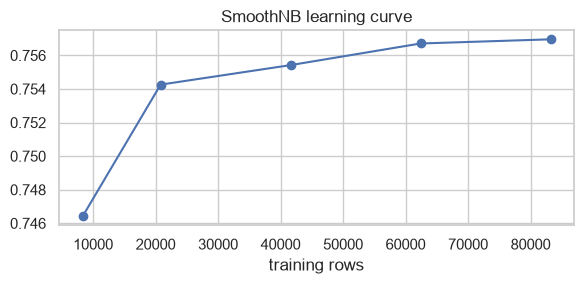

In [24]:
rng = np.random.default_rng(0); curve = []
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    p = np.zeros((len(y), 4))
    for tr, va in folds:
        sub = rng.choice(tr, int(len(tr) * frac), replace=False)
        f = FeatureBuilder(**VIEWS["nb"]).fit(train.iloc[sub])
        p[va] = SmoothNB(**SMOOTH).fit(f.transform(train.iloc[sub]), y[sub]).predict_proba(f.transform(train.iloc[va]))
    curve.append({"training rows": len(sub), "macro F1": f1_score(y, p.argmax(1), average="macro")})
curve = pd.DataFrame(curve); display(curve.round(4))
ax = curve.plot(x="training rows", y="macro F1", marker="o", legend=False, figsize=(6, 3)); ax.set_title("SmoothNB learning curve")
plt.tight_layout(); plt.show()

The curve has flattened: doubling the data from about 42k to 83k rows adds only about +0.002.

### 7.2 Calibration and label noise

In [25]:
p = oof["SmoothNB"]; conf = p.max(1); correct = p.argmax(1) == y
bins = [0, .4, .5, .6, .7, .8, .9, .95, .99, 1.01]
cal = pd.DataFrame({"bin": pd.cut(conf, bins, right=False), "conf": conf, "correct": correct}).groupby("bin", observed=True).agg(
    players=("conf", "size"), model_confidence=("conf", "mean"), actual_accuracy=("correct", "mean"))
display(cal.round(3))

,players,model_confidence,actual_accuracy
bin,,,
"[0.0, 0.4)",2123,0.360,0.377
"[0.4, 0.5)",6087,0.460,0.460
"[0.5, 0.6)",13475,0.550,0.554
"[0.6, 0.7)",13572,0.650,0.653
"[0.7, 0.8)",15101,0.751,0.756
"[0.8, 0.9)",19370,0.853,0.852
"[0.9, 0.95)",13901,0.926,0.921
"[0.95, 0.99)",16536,0.971,0.956
"[0.99, 1.01)",3835,0.994,0.969


The model's confidence matches its accuracy closely, except at the very top: players it is **99% sure** about are right only about **97%** of the time.
That is consistent with about **3% of labels being randomly flipped**, as was confirmed in the original data. No model can predict those.

**Conclusion:** classes overlap heavily, the features are independent given the segment (so Naive Bayes is near-optimal),
more data barely helps, and some labels are noise. The realistic ceiling is about 0.759–0.76, and we are within about 0.002 of it.

## 8. Final model and prediction file
**SmoothNB + spline logistic regression**, blended in log space with weights fitted on out-of-fold predictions, plus per-class weights.
Both models are refitted on all training rows and applied to the test set.

In [26]:
members = ["SmoothNB", "SplineLR"]
final_models = {"SmoothNB": (SmoothNB(**SMOOTH), VIEWS["nb"]), "SplineLR": (build("SplineLR", TUNED["SplineLR"]), VIEWS["lr"])}
w = fit_blend_weights([oof[m] for m in members], y)
cw = fit_class_weights(blend([oof[m] for m in members], w), y)[0]
print("blend weights:", dict(zip(members, w.round(3))), " class weights:", cw.round(3))

test_probs = []
for m in members:
    model, view = final_models[m]
    f = FeatureBuilder(**view).fit(train)
    Xtr, Xte = f.transform(train), f.transform(test)
    assert ID_COL not in Xtr.columns
    test_probs.append(model.fit(Xtr, y).predict_proba(Xte))
test_pred = apply_class_weights(blend(test_probs, w), cw)

oof_pred = apply_class_weights(blend([oof[m] for m in members], w), cw)
print(classification_report(y, oof_pred, target_names=ORDER, digits=4))
display(pd.DataFrame(confusion_matrix(y, oof_pred, normalize="true"), index=ORDER, columns=ORDER).round(3))
display(pd.DataFrame({"train (true)": seg.value_counts(normalize=True),
                      "test (predicted)": pd.Series(test_pred).map(CLASS_NAMES).value_counts(normalize=True)}).loc[ORDER].round(3))

pd.DataFrame({ID_COL: test[ID_COL], "task2": test_pred}).to_csv("task2_prediction.csv", index=False)
print("saved task2_prediction.csv:", len(test_pred), "rows")

blend weights: {'SmoothNB': np.float64(0.547), 'SplineLR': np.float64(0.386)}  class weights: [1.    1.051 1.    1.   ]


              precision    recall  f1-score   support

      Casual     0.7965    0.8526    0.8236     40957
     Grinder     0.7463    0.7477    0.7470     26032
      Social     0.7453    0.6853    0.7141     21029
       Whale     0.7762    0.7161    0.7449     15982

    accuracy                         0.7715    104000
   macro avg     0.7661    0.7504    0.7574    104000
weighted avg     0.7705    0.7715    0.7702    104000



,Casual,Grinder,Social,Whale
Casual,0.853,0.091,0.050,0.006
Grinder,0.179,0.748,0.028,0.045
Social,0.175,0.050,0.685,0.089
Whale,0.037,0.115,0.132,0.716


,train (true),test (predicted)
Casual,0.394,0.424
Grinder,0.250,0.251
Social,0.202,0.183
Whale,0.154,0.142


saved task2_prediction.csv: 25889 rows


## 9. Conclusions
**What worked**
- Understanding how the data was generated mattered more than any model choice: segment → independent features → Naive Bayes is near-optimal.
- From-scratch Naive Bayes with smoothed densities beat tuned LightGBM, XGBoost, CatBoost and Random Forest, and runs in seconds.
- Strict leak-free evaluation: features fitted in-fold, separate tuning folds, nested CV for blends and class weights. CV matched the leaderboard.

**What didn't**
- SMOTE and balanced class weights (they hurt macro F1), ratio features, stacking and tree-model blends (no gain).

**Common mistakes avoided**
- Using `player_id`, which leaked the label in the original release.
- Dropping rows with missing values (98% of rows have at least one).
- Trusting `player_type_tag`, which sounds relevant but is noise.

**Business interpretation**
- The 2×2 grid maps directly to campaigns: engagement-based offers (tournaments, ranked rewards) for Grinders, cosmetic and social offers for Socials, VIP treatment for Whales, light re-engagement for Casuals.
- `loyalty_tier` is the strongest single spending clue. When it is missing, accuracy drops sharply, so collecting it reliably would improve targeting.
- About a quarter of players sit in the overlap zone (model confidence below 0.6). For them, campaigns that suit two adjacent segments are safer than a hard assignment.

**Future improvements**
- Remaining headroom is only about +0.002. Better per-feature density estimates or a noise-aware model would be the only levers left.